<a href="https://colab.research.google.com/github/lingga26/machine_learning_prediksi_saham/blob/main/prediksi_harga_saham.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install xgboost

In [ ]:
from google.colab import files

uploaded = files.upload()

TypeError: 'NoneType' object is not subscriptable

In [ ]:
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math

#1 gabungan data roburst
file_list = [
    'datasheeet bbri.csv',
]



Memulai penggabungan dan pembersihan data...
Total data yang digunakan: 1213 baris.
Total data setelah Feature Engineering: 1206 baris.

--- Pelatihan Decision Tree Regressor ---
--- Pelatihan XGBoost Regressor ---


/usr/local/lib/python3.12/dist-packages/pandas/core/indexes/base.py:7588: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)



---------------- LAPORAN KINERJA MODEL ----------------
Decision Tree RMSE: IDR 0.17
XGBoost RMSE: IDR 0.11
-------------------------------------------------------


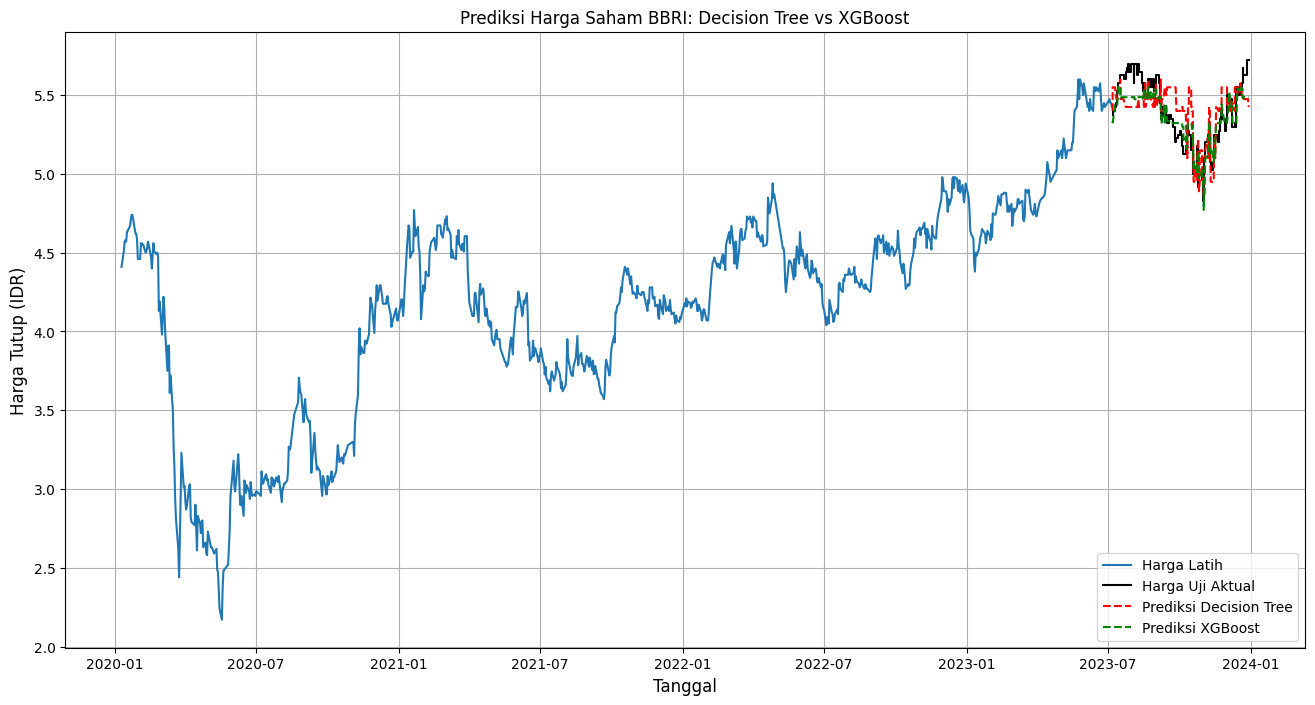

In [ ]:

all_data = []

def clean_currency(val):
    if isinstance(val, str):
        val = val.replace('.', '').replace(',', '.')
    try:
        return float(val)
    except (ValueError, TypeError):
        return np.nan

print("Memulai penggabungan dan pembersihan data...")
for file in file_list:
    try:
        # encoding
        df_temp = pd.read_csv(file, encoding='utf-8-sig', quotechar='"')
        all_data.append(df_temp)
    except FileNotFoundError:
        continue
    except Exception as e:
        print(f"Error saat membaca file {file}: {e}")
        continue

df = pd.concat(all_data, ignore_index=True)

# Membersihkan nama kolom (strip)
df.columns = df.columns.str.strip().str.replace('"', '')

# Menemukan dan menamai ulang kolom secara paksa (Solusi Key Error)
try:
    date_column = [col for col in df.columns if 'tanggal' in col.lower()][0]
    last_column = [col for col in df.columns if 'terakhir' in col.lower()][0]
    df.rename(columns={date_column: 'Tanggal', last_column: 'Terakhir'}, inplace=True)
except IndexError:
    print("[ERROR] Kolom 'Tanggal' atau 'Terakhir' tidak ditemukan meskipun sudah dibersihkan.")
    exit()

# Mengubah format tanggal dan mengurutkan
df.loc[:, 'Tanggal'] = pd.to_datetime(df['Tanggal'], format='%d/%m/%Y', errors='coerce')
df = df.sort_values('Tanggal', ascending=True).reset_index(drop=True)

# Menerapkan fungsi pembersihan pada kolom harga 'Terakhir'
df.loc[:, 'Close'] = df['Terakhir'].apply(clean_currency)

# Menghapus baris yang mungkin menjadi NaN (data yang tidak valid)
df.dropna(subset=['Close', 'Tanggal'], inplace=True)

data_to_use = df[['Tanggal', 'Close']].set_index('Tanggal')
print(f"Total data yang digunakan: {len(data_to_use)} baris.")

# --- 2. FEATURE ENGINEERING (PENTING UNTUK MODEL TREE-BASED) ---

# Membuat fitur baru (variabel independen X)
# 1. Target Prediksi (Variabel dependen Y): Harga tutup 1 periode ke depan
PREDICTION_PERIOD = 1
data_to_use['Target'] = data_to_use['Close'].shift(-PREDICTION_PERIOD)

# 2. Fitur Lag (Harga Tutup Bulan Sebelumnya)
LAG_FEATURES = [1, 2, 3, 6] # Menggunakan harga tutup 1, 2, 3, dan 6 bulan sebelumnya
for lag in LAG_FEATURES:
    data_to_use[f'Lag_{lag}'] = data_to_use['Close'].shift(lag)

# 3. Fitur Moving Average
data_to_use['MA_3'] = data_to_use['Close'].rolling(window=3).mean().shift(1)
data_to_use['MA_6'] = data_to_use['Close'].rolling(window=6).mean().shift(1)

# Hapus baris yang mengandung NaN yang dihasilkan dari Lag dan MA
data_to_use.dropna(inplace=True)
print(f"Total data setelah Feature Engineering: {len(data_to_use)} baris.")

# Mendefinisikan X dan Y
X = data_to_use.drop('Target', axis=1).values
Y = data_to_use['Target'].values

# --- 3. PEMBAGIAN DATA ---

# Rasio data latih 80%
training_data_len = int(np.ceil(len(data_to_use) * 0.80))

X_train = X[:training_data_len]
Y_train = Y[:training_data_len]
X_test = X[training_data_len:]
Y_test = Y[training_data_len:]

# --- 4. PELATIHAN DAN EVALUASI MODEL ---

results = {}

# --- MODEL 1: DECISION TREE REGRESSOR ---
print("\n--- Pelatihan Decision Tree Regressor ---")
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, Y_train)
dt_predictions = dt_model.predict(X_test)
dt_rmse = math.sqrt(mean_squared_error(Y_test, dt_predictions))
results['Decision Tree'] = dt_predictions

# --- MODEL 2: XGBOOST REGRESSOR ---
print("--- Pelatihan XGBoost Regressor ---")
xgb_model = XGBRegressor(objective='reg:squarederror', n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train, Y_train)
xgb_predictions = xgb_model.predict(X_test)
xgb_rmse = math.sqrt(mean_squared_error(Y_test, xgb_predictions))
results['XGBoost'] = xgb_predictions

# --- 5. VISUALISASI DAN LAPORAN HASIL ---

print("\n---------------- LAPORAN KINERJA MODEL ----------------")
print(f"Decision Tree RMSE: IDR {dt_rmse:.2f}")
print(f"XGBoost RMSE: IDR {xgb_rmse:.2f}")
print("-------------------------------------------------------")

# Menggabungkan hasil prediksi dengan data aktual
valid_df = data_to_use.iloc[training_data_len:].copy()
valid_df['Actual'] = Y_test
valid_df['DT_Prediction'] = dt_predictions
valid_df['XGBoost_Prediction'] = xgb_predictions

# Visualisasi
plt.figure(figsize=(16, 8))
plt.title('Prediksi Harga Saham BBRI: Decision Tree vs XGBoost')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Harga Tutup (IDR)', fontsize=12)

plt.plot(data_to_use[:training_data_len]['Close'], label='Harga Latih')
plt.plot(valid_df['Actual'], label='Harga Uji Aktual', color='black')
plt.plot(valid_df['DT_Prediction'], label='Prediksi Decision Tree', color='red', linestyle='--')
plt.plot(valid_df['XGBoost_Prediction'], label='Prediksi XGBoost', color='green', linestyle='--')

plt.legend(loc='lower right')
plt.grid(True)
plt.show()